In [1]:
import torch

print("PyTorch Version:", torch.__version__)

if torch.cuda.is_available():
    print("GPU Available:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")

PyTorch Version: 2.14.1+cu130
GPU Available: Tesla T4


In [2]:
!pip install SoccerNet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.3/16.3 MB 63.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.3/104.3 MB 38.5 MB/s  0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 38.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [SoccerNet]


In [3]:
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms

print("All libraries imported successfully!")
print("GPU:", torch.cuda.get_device_name(0))

All libraries imported successfully!
GPU: Tesla T4


In [4]:
from SoccerNet.Downloader import SoccerNetDownloader

downloader = SoccerNetDownloader(LocalDirectory="SoccerNet")
downloader.downloadGames(
    files=["Labels-v2.json"],
    split=["train", "valid", "test"]
)

print("Annotation download completed!")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 300 files:   0%|          | 0/300 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 100 files:   0%|          | 0/100 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 100 files:   0%|          | 0/100 [00:00<?, ?it/s]

Annotation download completed!


In [5]:
import os

for root, dirs, files in os.walk("SoccerNet"):
    for file in files:
        if file == "Labels-v2.json":
            print("Found:", os.path.join(root, file))

Found: SoccerNet/england_epl/2014-2015/2015-02-21 - 18-00 Chelsea 1 - 1 Burnley/Labels-v2.json
Found: SoccerNet/england_epl/2014-2015/2015-02-21 - 18-00 Swansea 2 - 1 Manchester United/Labels-v2.json
Found: SoccerNet/england_epl/2014-2015/2015-02-22 - 19-15 Southampton 0 - 2 Liverpool/Labels-v2.json
Found: SoccerNet/england_epl/2014-2015/2015-02-21 - 18-00 Crystal Palace 1 - 2 Arsenal/Labels-v2.json
Found: SoccerNet/england_epl/2014-2015/2015-05-17 - 18-00 Manchester United 1 - 1 Arsenal/Labels-v2.json
Found: SoccerNet/england_epl/2014-2015/2015-04-11 - 19-30 Burnley 0 - 1 Arsenal/Labels-v2.json
Found: SoccerNet/england_epl/2015-2016/2015-09-12 - 14-45 Everton 3 - 1 Chelsea/Labels-v2.json
Found: SoccerNet/england_epl/2015-2016/2015-10-24 - 17-00 West Ham 2 - 1 Chelsea/Labels-v2.json
Found: SoccerNet/england_epl/2015-2016/2015-09-26 - 17-00 Liverpool 3 - 2 Aston Villa/Labels-v2.json
Found: SoccerNet/england_epl/2015-2016/2016-05-07 - 17-00 Sunderland 3 - 2 Chelsea/Labels-v2.json
Found: 

In [6]:
import glob
import json

files = glob.glob("SoccerNet/**/Labels-v2.json", recursive=True)

print("Total annotation files:", len(files))

# Open the first annotation file
with open(files[0], "r") as f:
    data = json.load(f)

print("\nTop-level keys:")
print(data.keys())

print("\nFirst 3 annotations:")
for event in data["annotations"][:3]:
    print(event)

Total annotation files: 500

Top-level keys:
dict_keys(['UrlLocal', 'UrlYoutube', 'annotations', 'gameAwayTeam', 'gameDate', 'gameHomeTeam', 'gameScore'])

First 3 annotations:
{'gameTime': '1 - 00:00', 'label': 'Kick-off', 'position': '0', 'team': 'away', 'visibility': 'visible'}
{'gameTime': '1 - 02:13', 'label': 'Ball out of play', 'position': '133295', 'team': 'not applicable', 'visibility': 'visible'}
{'gameTime': '1 - 02:29', 'label': 'Throw-in', 'position': '149168', 'team': 'away', 'visibility': 'visible'}


In [7]:
import glob
import json
from collections import Counter

files = glob.glob("SoccerNet/**/Labels-v2.json", recursive=True)

label_counts = Counter()

for file in files:
    with open(file, "r") as f:
        data = json.load(f)

    for event in data["annotations"]:
        label_counts[event["label"]] += 1

print("Total event categories:", len(label_counts))
print("\nMost common 20 events:\n")

for label, count in label_counts.most_common(20):
    print(label, ":", count)

Total event categories: 17

Most common 20 events:

Ball out of play : 31810
Throw-in : 18918
Foul : 11674
Indirect free-kick : 10521
Clearance : 7896
Shots on target : 5820
Shots off target : 5256
Corner : 4836
Substitution : 2839
Kick-off : 2566
Direct free-kick : 2200
Offside : 2098
Yellow card : 2047
Goal : 1703
Penalty : 173
Red card : 55
Yellow->red card : 46


In [8]:
import glob

videos = glob.glob(
    "SoccerNet/**/*.mp4",
    recursive=True
)

print("Total video files:", len(videos))

for video in videos[:10]:
    print(video)

Total video files: 0


In [9]:
!pip install yt-dlp

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 14.8 MB/s  0:00:00


In [10]:
import os

os.makedirs("football_videos", exist_ok=True)

print("Video folder created successfully!")

Video folder created successfully!


In [11]:
from SoccerNet.Downloader import SoccerNetDownloader

downloader = SoccerNetDownloader(LocalDirectory="SoccerNet")

print("SoccerNet downloader is ready!")

SoccerNet downloader is ready!


In [12]:
import os

matches = []

for root, dirs, files in os.walk("SoccerNet"):
    if "Labels-v2.json" in files:
        matches.append(root)

print("Total matches with annotations:", len(matches))
print("\nFirst 5 matches:")

for match in matches[:5]:
    print(match)

Total matches with annotations: 500

First 5 matches:
SoccerNet/england_epl/2014-2015/2015-02-21 - 18-00 Chelsea 1 - 1 Burnley
SoccerNet/england_epl/2014-2015/2015-02-21 - 18-00 Swansea 2 - 1 Manchester United
SoccerNet/england_epl/2014-2015/2015-02-22 - 19-15 Southampton 0 - 2 Liverpool
SoccerNet/england_epl/2014-2015/2015-02-21 - 18-00 Crystal Palace 1 - 2 Arsenal
SoccerNet/england_epl/2014-2015/2015-05-17 - 18-00 Manchester United 1 - 1 Arsenal


In [13]:
import glob

video_files = []

for extension in ["mkv", "mp4", "avi"]:
    video_files.extend(
        glob.glob(f"SoccerNet/**/*.{extension}", recursive=True)
    )

print("Total video files:", len(video_files))

for video in video_files[:10]:
    print(video)

Total video files: 0


In [14]:
!python -m pip show SoccerNet

Name: SoccerNet
Version: 0.2.0
Summary: SoccerNet SDK
Home-page: https://github.com/SoccerNet/SoccerNet
Author: Silvio Giancola
Author-email: silvio.giancola@kaust.edu.sa
License: MIT
Location: /usr/local/lib/python3.13/dist-packages
Requires: boto3, google-measurement-protocol, huggingface_hub, matplotlib, pycocoevalcap, scikit-video, tqdm
Required-by: 


In [15]:
import inspect
from SoccerNet.Downloader import SoccerNetDownloader

print(inspect.signature(SoccerNetDownloader.downloadGames))
print("\nDownloader documentation:")
print(inspect.getdoc(SoccerNetDownloader.downloadGames))

(self, files=['1.mkv', '2.mkv', 'Labels.json'], split=['train', 'valid', 'test'], task='spotting', verbose=True, randomized=False, source='HuggingFace')

Downloader documentation:
None


In [18]:
from SoccerNet.Downloader import SoccerNetDownloader

downloader = SoccerNetDownloader(LocalDirectory="SoccerNet")

downloader.downloadGames(
    files=["1.mkv", "2.mkv"],
    split=["train"],
    task="spotting",
    verbose=True
)

PermissionError: Could not download from 'SoccerNet/SoccerNet_raw_HQ' on Hugging Face (404 Client Error. (Request ID: Root=1-6af5d08b-1a1ef4541a3cf70763c29e07;896a29f6-35cb-4b28-90b4-d4cbcf9c707b)

Revision Not Found for url: https://huggingface.co/api/datasets/SoccerNet/SoccerNet_raw_HQ/revision/videos-LQ.
Invalid rev id: videos-LQ). If this dataset is gated or private, request access at https://huggingface.co/datasets/SoccerNet/SoccerNet_raw_HQ and make sure you are logged in with a granted account (`huggingface-cli login`), then try again.

In [19]:
import glob
import json

files = glob.glob(
    "SoccerNet/**/Labels-v2.json",
    recursive=True
)

with open(files[0], "r") as f:
    data = json.load(f)

print("Match:", data["gameHomeTeam"], "vs", data["gameAwayTeam"])
print("YouTube link:", data["UrlYoutube"])

Match: Chelsea vs Burnley
YouTube link: 


In [20]:
import glob
import json

files = glob.glob(
    "SoccerNet/**/Labels-v2.json",
    recursive=True
)

count = 0

for file in files:
    with open(file, "r") as f:
        data = json.load(f)

    link = data.get("UrlYoutube", "")

    if link:
        print(data["gameHomeTeam"], "vs", data["gameAwayTeam"])
        print("Link:", link)
        print()
        count += 1

    if count == 5:
        break

print("Matches with links found:", count)

Matches with links found: 0


In [21]:
import os
import torch
import cv2
import torchvision

# Create project folders
os.makedirs("/content/sports_action/data", exist_ok=True)
os.makedirs("/content/sports_action/frames", exist_ok=True)
os.makedirs("/content/sports_action/models", exist_ok=True)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("OpenCV:", cv2.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Project folders created successfully!")

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
OpenCV: 4.14.0
GPU available: True
GPU: Tesla T4
Project folders created successfully!


In [22]:
import os
import urllib.request

url = "https://www.crcv.ucf.edu/data/UCF101/UCF101.rar"
output_path = "/content/sports_action/UCF101.rar"

if not os.path.exists(output_path):
    print("Downloading UCF101 dataset...")
    urllib.request.urlretrieve(url, output_path)

print("Download completed!")
print("File size:", round(os.path.getsize(output_path) / (1024**3), 2), "GB")

ContentTooShortError: <urlopen error retrieval incomplete: got only 1084358179 out of 6932971618 bytes>

In [24]:
import os

file_path = "/content/sports_action/UCF101.rar"

print("Existing downloaded size:",
      round(os.path.getsize(file_path) / (1024**3), 2), "GB")

!wget -c https://www.crcv.ucf.edu/data/UCF101/UCF101.rar -O /content/sports_action/UCF101.rar

print("Final file size:",
      round(os.path.getsize(file_path) / (1024**3), 2), "GB")

Existing downloaded size: 6.46 GB
--2026-11-12 14:56:52--  https://www.crcv.ucf.edu/data/UCF101/UCF101.rar
Resolving www.crcv.ucf.edu (www.crcv.ucf.edu)... 132.170.214.127
Connecting to www.crcv.ucf.edu (www.crcv.ucf.edu)|132.170.214.127|:443... connected.
HTTP request sent, awaiting response... 416 Requested Range Not Satisfiable

    The file is already fully retrieved; nothing to do.

Final file size: 6.46 GB


In [25]:
import os

file_path = "/content/sports_action/UCF101.rar"
expected_size = 6932971618
actual_size = os.path.getsize(file_path)

print("Expected size:", expected_size, "bytes")
print("Actual size:", actual_size, "bytes")

if actual_size == expected_size:
    print("File size matches! Checking archive integrity...")
else:
    print("File size does not match. Download may be incomplete.")

Expected size: 6932971618 bytes
Actual size: 6932971618 bytes
File size matches! Checking archive integrity...


In [26]:

!apt-get -qq update
!apt-get -qq install -y p7zip-full

!7z t /content/sports_action/UCF101.rar

Streaming output truncated to the last 5000 lines.
 61% T UCF-101/PlayingFlute/v_PlayingFlute_g25_c07.avi                                                      ERROR: Unsupported Method : UCF-101/PlayingGuitar/v_PlayingGuitar_g01_c01.avi
 61% T UCF-101/PlayingGuitar/v_PlayingGuitar_g01_c01.avi                                                        ERROR: Unsupported Method : UCF-101/PlayingGuitar/v_PlayingGuitar_g01_c02.avi
 61% T UCF-101/PlayingGuitar/v_PlayingGuitar_g01_c02.avi                                                        ERROR: Unsupported Method : UCF-101/PlayingGuitar/v_PlayingGuitar_g01_c03.avi
 61% T UCF-101/PlayingGuitar/v_PlayingGuitar_g01_c0

In [27]:
!apt-get update -qq
!apt-get install -y unar

print("Unarchiver installation completed!")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  gnustep-base-common gnustep-base-runtime gnustep-common gnutls-bin libgc1
  libgnustep-base1.29 libgnutls-dane0t64 libgnutls30t64 libobjc4 libunbound8
  libwavpack1 tzdata-legacy
Suggested packages:
  dns-root-data
The following NEW packages will be installed:
  gnustep-base-common gnustep-base-runtime gnustep-common gnutls-bin libgc1
  libgnustep-base1.29 libgnutls-dane0t64 libobjc4 libunbound8 libwavpack1
  tzdata-legacy unar
The following packages will be upgraded:
  libgnutls30t64
1 upgraded, 12 newly installed, 0 to remove and 87 not upgraded.
Need to get 5,326 kB of archives.
After this operation, 19.0 MB of additional disk space will be used.
G

In [28]:
!unar -t /content/sports_action/UCF101.rar

Streaming output truncated to the last 5000 lines.
  UCF-101/PlayingGuitar/v_PlayingGuitar_g16_c02.avi  (655812 B)... OK.
  UCF-101/PlayingGuitar/v_PlayingGuitar_g16_c03.avi  (658354 B)... OK.
  UCF-101/PlayingGuitar/v_PlayingGuitar_g16_c04.avi  (649744 B)... OK.
  UCF-101/PlayingGuitar/v_PlayingGuitar_g16_c05.avi  (650474 B)... OK.
  UCF-101/PlayingGuitar/v_PlayingGuitar_g16_c06.avi  (644696 B)... OK.
  UCF-101/PlayingGuitar/v_PlayingGuitar_g16_c07.avi  (659828 B)... OK.
  UCF-101/PlayingGuitar/v_PlayingGuitar_g17_c01.avi  (639272 B)... OK.
  UCF-101/PlayingGuitar/v_PlayingGuitar_g17_c02.avi  (627694 B)... OK.
  UCF-101/PlayingGuitar/v_PlayingGuitar_g17_c03.avi  (608632 B)... OK.
  UCF-101/PlayingGuitar/v_PlayingGuitar_g17_c04.avi  (629416 B)... OK.
  UCF-101/PlayingGuitar/v_PlayingGuitar_g17_c05.avi  (645396 B)... OK.
  UCF-101/PlayingGuitar/v_PlayingGuitar_g17_c06.avi  (617526 B)... OK.
  UCF-101/PlayingGuitar/v_PlayingGuitar_g17_c07.avi  (610982 B)... OK.
  UCF-101/PlayingGuitar/v_

In [29]:
!lsar /content/sports_action/UCF101.rar | grep -E 'UCF-101/(Basketball|BasketballDunk|Biking|SoccerJuggling|TennisSwing|VolleyballSpiking)/' | head -20

UCF-101/Basketball/v_Basketball_g01_c01.avi
UCF-101/Basketball/v_Basketball_g01_c02.avi
UCF-101/Basketball/v_Basketball_g01_c03.avi
UCF-101/Basketball/v_Basketball_g01_c04.avi
UCF-101/Basketball/v_Basketball_g01_c05.avi
UCF-101/Basketball/v_Basketball_g01_c06.avi
UCF-101/Basketball/v_Basketball_g01_c07.avi
UCF-101/Basketball/v_Basketball_g02_c01.avi
UCF-101/Basketball/v_Basketball_g02_c02.avi
UCF-101/Basketball/v_Basketball_g02_c03.avi
UCF-101/Basketball/v_Basketball_g02_c04.avi
UCF-101/Basketball/v_Basketball_g02_c05.avi
UCF-101/Basketball/v_Basketball_g02_c06.avi
UCF-101/Basketball/v_Basketball_g03_c01.avi
UCF-101/Basketball/v_Basketball_g03_c02.avi
UCF-101/Basketball/v_Basketball_g03_c03.avi
UCF-101/Basketball/v_Basketball_g03_c04.avi
UCF-101/Basketball/v_Basketball_g03_c05.avi
UCF-101/Basketball/v_Basketball_g03_c06.avi
UCF-101/Basketball/v_Basketball_g04_c01.avi


In [30]:
!lsar /content/sports_action/UCF101.rar | grep -E '^UCF-101/(Basketball|BasketballDunk|SoccerJuggling|TennisSwing|VolleyballSpiking|Biking)/' | cut -d/ -f2 | sort -u

Basketball
BasketballDunk
Biking
SoccerJuggling
TennisSwing
VolleyballSpiking


In [31]:
!unar -h

unar v1.10.1, a tool for extracting the contents of archive files.
Usage: unar [options] archive [files ...]

Available options:
-output-directory (-o) <string>    The
                                   directory
                                   to
                                   write
                                   the
                                   contents
                                   of
                                   the
                                   archive
                                   to.
                                   Defaults
                                   to
                                   the
                                   current
                                   directory.
                                   If
                                   set
                                   to
                                   a
                                   single
                                   dash
                      

In [32]:
!mkdir -p /content/sports_action/data

!unar -f -o /content/sports_action/data \
/content/sports_action/UCF101.rar \
'UCF-101/Basketball/*' \
'UCF-101/BasketballDunk/*' \
'UCF-101/Biking/*' \
'UCF-101/SoccerJuggling/*' \
'UCF-101/TennisSwing/*' \
'UCF-101/VolleyballSpiking/*'

/content/sports_action/UCF101.rar: RAR
  UCF-101/Basketball/v_Basketball_g01_c01.avi  (287972 B)... OK.
  UCF-101/Basketball/v_Basketball_g01_c02.avi  (350364 B)... OK.
  UCF-101/Basketball/v_Basketball_g01_c03.avi  (381248 B)... OK.
  UCF-101/Basketball/v_Basketball_g01_c04.avi  (216846 B)... OK.
  UCF-101/Basketball/v_Basketball_g01_c05.avi  (266872 B)... OK.
  UCF-101/Basketball/v_Basketball_g01_c06.avi  (265144 B)... OK.
  UCF-101/Basketball/v_Basketball_g01_c07.avi  (211852 B)... OK.
  UCF-101/Basketball/v_Basketball_g02_c01.avi  (109278 B)... OK.
  UCF-101/Basketball/v_Basketball_g02_c02.avi  (114802 B)... OK.
  UCF-101/Basketball/v_Basketball_g02_c03.avi  (233874 B)... OK.
  UCF-101/Basketball/v_Basketball_g02_c04.avi  (159926 B)... OK.
  UCF-101/Basketball/v_Basketball_g02_c05.avi  (288606 B)... OK.
  UCF-101/Basketball/v_Basketball_g02_c06.avi  (238056 B)... OK.
  UCF-101/Basketball/v_Basketball_g03_c01.avi  (331660 B)... OK.
  UCF-101/Basketball/v_Basketball_g03_c02.avi  (313

In [33]:
import os

data_dir = "/content/sports_action/data/UCF-101"

classes = [
    "Basketball",
    "BasketballDunk",
    "Biking",
    "SoccerJuggling",
    "TennisSwing",
    "VolleyballSpiking"
]

total = 0

for cls in classes:
    folder = os.path.join(data_dir, cls)
    videos = [
        f for f in os.listdir(folder)
        if f.endswith(".avi")
    ]
    print(f"{cls}: {len(videos)} videos")
    total += len(videos)

print("\nTotal videos:", total)

Basketball: 134 videos
BasketballDunk: 131 videos
Biking: 134 videos
SoccerJuggling: 147 videos
TennisSwing: 166 videos
VolleyballSpiking: 116 videos

Total videos: 828


In [34]:
import os, cv2, numpy as np
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split

DATA_DIR = "/content/sports_action/data/UCF-101"
SAVE_DIR = "/content/sports_action/processed"
os.makedirs(SAVE_DIR, exist_ok=True)

classes = [
    "Basketball", "BasketballDunk", "Biking",
    "SoccerJuggling", "TennisSwing", "VolleyballSpiking"
]

videos, labels = [], []

for i, cls in enumerate(classes):
    folder = os.path.join(DATA_DIR, cls)
    for f in os.listdir(folder):
        if f.endswith(".avi"):
            videos.append(os.path.join(folder, f))
            labels.append(i)

videos, labels = np.array(videos), np.array(labels)

train_v, temp_v, train_y, temp_y = train_test_split(
    videos, labels, test_size=0.30, random_state=42, stratify=labels
)
val_v, test_v, val_y, test_y = train_test_split(
    temp_v, temp_y, test_size=0.50, random_state=42, stratify=temp_y
)

def extract(paths):
    result = []
    for path in tqdm(paths):
        cap = cv2.VideoCapture(path)
        n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        frames = []

        for p in np.linspace(0, max(0, n//2-1), 4).astype(int):
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(p))
            ret, frame = cap.read()
            if ret:
                frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                frames.append(cv2.resize(frame, (64, 64)))

        cap.release()
        if not frames:
            frames = [np.zeros((64,64,3), dtype=np.uint8)]
        while len(frames) < 4:
            frames.append(frames[-1])

        result.append(np.array(frames[:4]))

    return np.array(result, dtype=np.uint8)

X_train, X_val, X_test = extract(train_v), extract(val_v), extract(test_v)

np.savez_compressed(
    SAVE_DIR + "/sports_dataset.npz",
    X_train=X_train, X_val=X_val, X_test=X_test,
    y_train=train_y, y_val=val_y, y_test=test_y,
    classes=classes
)

print("TRAIN:", X_train.shape)
print("VALIDATION:", X_val.shape)
print("TEST:", X_test.shape)
print("Dataset ready!")

  0%|          | 0/579 [00:00<?, ?it/s]

  0%|          | 0/124 [00:00<?, ?it/s]

  0%|          | 0/125 [00:00<?, ?it/s]

TRAIN: (579, 4, 64, 64, 3)
VALIDATION: (124, 4, 64, 64, 3)
TEST: (125, 4, 64, 64, 3)
Dataset ready!


In [35]:
import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score
import copy
import time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

data = np.load("/content/sports_action/processed/sports_dataset.npz")

class SportsDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X).permute(0, 1, 4, 2, 3)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.X[i], self.y[i]

train_loader = DataLoader(
    SportsDataset(data["X_train"], data["y_train"]),
    batch_size=32, shuffle=True
)

val_loader = DataLoader(
    SportsDataset(data["X_val"], data["y_val"]),
    batch_size=32
)

class CNNEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten()
        )

    def forward(self, x):
        return self.net(x)

class SportsModel(nn.Module):
    def __init__(self, mode):
        super().__init__()
        self.mode = mode
        self.encoder = CNNEncoder()

        if mode == "GRU":
            self.temporal = nn.GRU(128, 128, batch_first=True)
        elif mode == "LSTM":
            self.temporal = nn.LSTM(128, 128, batch_first=True)

        self.classifier = nn.Linear(128, 6)

    def forward(self, x):
        b, t, c, h, w = x.shape
        x = x.reshape(b*t, c, h, w).float() / 255.0
        features = self.encoder(x).reshape(b, t, 128)

        if self.mode == "CNN":
            features = features.mean(dim=1)
        else:
            output, _ = self.temporal(features)
            features = output[:, -1, :]

        return self.classifier(features)

def train_model(mode, epochs=5):
    model = SportsModel(mode).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    best_acc = 0
    best_weights = copy.deepcopy(model.state_dict())
    history = []

    start = time.time()

    for epoch in range(epochs):
        model.train()
        total_loss = 0

        for X, y in train_loader:
            X, y = X.to(device), y.to(device)
            optimizer.zero_grad()
            output = model(X)
            loss = criterion(output, y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        model.eval()
        predictions, actual = [], []

        with torch.no_grad():
            for X, y in val_loader:
                output = model(X.to(device))
                predictions.extend(output.argmax(1).cpu().numpy())
                actual.extend(y.numpy())

        acc = accuracy_score(actual, predictions)
        history.append(acc)

        if acc > best_acc:
            best_acc = acc
            best_weights = copy.deepcopy(model.state_dict())

        print(
            f"{mode} Epoch {epoch+1}/{epochs} "
            f"Loss: {total_loss/len(train_loader):.4f} "
            f"Validation accuracy: {acc:.4f}"
        )

    model.load_state_dict(best_weights)
    print(f"{mode} best validation accuracy: {best_acc:.4f}")
    print(f"Time: {time.time()-start:.1f} seconds")

    return model, history, best_acc

models = {}
histories = {}
results = {}

for mode in ["CNN", "GRU", "LSTM"]:
    print("\nTraining", mode)
    models[mode], histories[mode], results[mode] = train_model(mode)

print("\nMODEL COMPARISON")
for name, score in results.items():
    print(name, "Validation accuracy:", round(score * 100, 2), "%")

Training device: cuda

Training CNN
CNN Epoch 1/5 Loss: 1.7792 Validation accuracy: 0.1935
CNN Epoch 2/5 Loss: 1.7037 Validation accuracy: 0.2661
CNN Epoch 3/5 Loss: 1.6246 Validation accuracy: 0.2823
CNN Epoch 4/5 Loss: 1.5714 Validation accuracy: 0.3065
CNN Epoch 5/5 Loss: 1.5325 Validation accuracy: 0.3387
CNN best validation accuracy: 0.3387
Time: 5.4 seconds

Training GRU
GRU Epoch 1/5 Loss: 1.7845 Validation accuracy: 0.2903
GRU Epoch 2/5 Loss: 1.6852 Validation accuracy: 0.3226
GRU Epoch 3/5 Loss: 1.5976 Validation accuracy: 0.3065
GRU Epoch 4/5 Loss: 1.5047 Validation accuracy: 0.3145
GRU Epoch 5/5 Loss: 1.4446 Validation accuracy: 0.3145
GRU best validation accuracy: 0.3226
Time: 2.0 seconds

Training LSTM
LSTM Epoch 1/5 Loss: 1.7871 Validation accuracy: 0.2016
LSTM Epoch 2/5 Loss: 1.7481 Validation accuracy: 0.3065
LSTM Epoch 3/5 Loss: 1.6164 Validation accuracy: 0.2581
LSTM Epoch 4/5 Loss: 1.6704 Validation accuracy: 0.2581
LSTM Epoch 5/5 Loss: 1.5514 Validation accuracy: 0.


CNN TEST RESULTS
Accuracy: 31.2 %
                   precision    recall  f1-score   support

       Basketball       0.00      0.00      0.00        20
   BasketballDunk       0.31      1.00      0.47        20
           Biking       0.00      0.00      0.00        20
   SoccerJuggling       0.21      0.32      0.25        22
      TennisSwing       0.46      0.48      0.47        25
VolleyballSpiking       0.00      0.00      0.00        18

         accuracy                           0.31       125
        macro avg       0.16      0.30      0.20       125
     weighted avg       0.18      0.31      0.21       125


GRU TEST RESULTS
Accuracy: 31.2 %
                   precision    recall  f1-score   support

       Basketball       0.00      0.00      0.00        20
   BasketballDunk       0.50      0.90      0.64        20
           Biking       0.00      0.00      0.00        20
   SoccerJuggling       0.00      0.00      0.00        22
      TennisSwing       0.24      0.84   

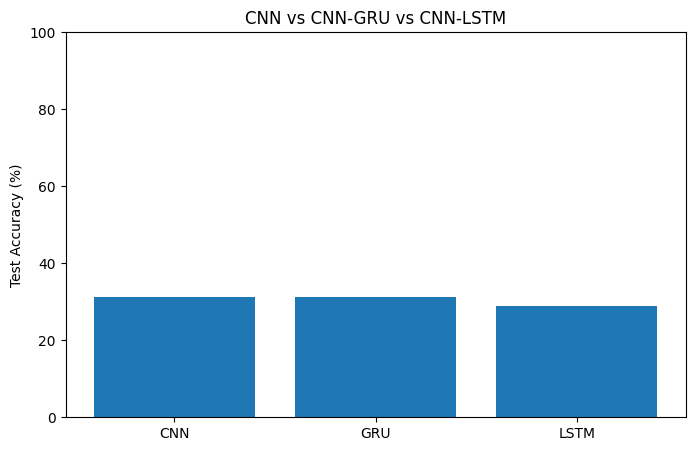

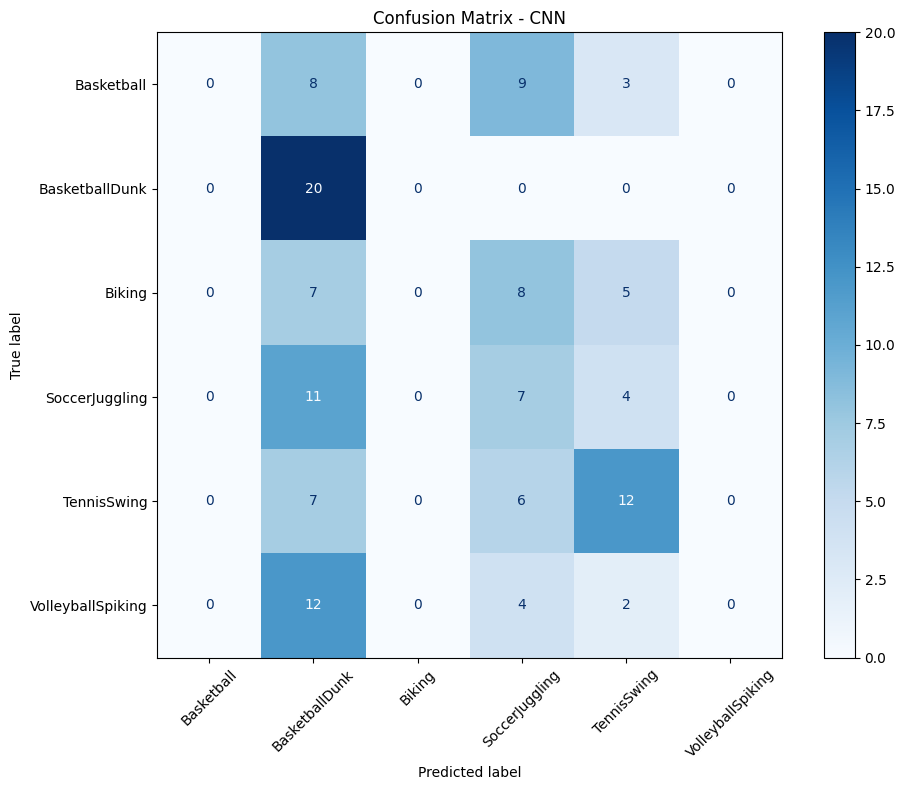


FINAL TEST ACCURACY
CNN: 31.20%
GRU: 31.20%
LSTM: 28.80%
Best validation model: CNN


In [37]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

test_loader = DataLoader(
    SportsDataset(data["X_test"], data["y_test"]),
    batch_size=32, shuffle=False
)

test_results = {}
all_predictions = {}

for name, model in models.items():
    model.eval()
    predictions, actual = [], []

    with torch.no_grad():
        for X, y in test_loader:
            output = model(X.to(device))
            predictions.extend(output.argmax(1).cpu().numpy())
            actual.extend(y.numpy())

    test_results[name] = accuracy_score(actual, predictions)
    all_predictions[name] = predictions

    print(f"\n{name} TEST RESULTS")
    print("Accuracy:", round(test_results[name] * 100, 2), "%")
    print(classification_report(
        actual, predictions,
        labels=list(range(6)),
        target_names=classes,
        zero_division=0
    ))

# Model comparison graph
plt.figure(figsize=(8, 5))
names = list(test_results.keys())
scores = [test_results[n] * 100 for n in names]

plt.bar(names, scores)
plt.ylabel("Test Accuracy (%)")
plt.title("CNN vs CNN-GRU vs CNN-LSTM")
plt.ylim(0, 100)
plt.savefig("/content/sports_action/model_comparison.png")
plt.show()

# Confusion matrix for best validation model
best_name = max(results, key=results.get)
best_predictions = all_predictions[best_name]

cm = confusion_matrix(
    data["y_test"], best_predictions,
    labels=list(range(6))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues")
plt.title(f"Confusion Matrix - {best_name}")
plt.tight_layout()
plt.savefig("/content/sports_action/confusion_matrix.png")
plt.show()

print("\nFINAL TEST ACCURACY")
for name, score in test_results.items():
    print(f"{name}: {score*100:.2f}%")

print("Best validation model:", best_name)

Adam Epoch 1: Validation accuracy = 0.2016
Adam Epoch 2: Validation accuracy = 0.2258
Adam Epoch 3: Validation accuracy = 0.2742
Adam Epoch 4: Validation accuracy = 0.3387
Adam Epoch 5: Validation accuracy = 0.3226
SGD Epoch 1: Validation accuracy = 0.2016
SGD Epoch 2: Validation accuracy = 0.2016
SGD Epoch 3: Validation accuracy = 0.2016
SGD Epoch 4: Validation accuracy = 0.2016
SGD Epoch 5: Validation accuracy = 0.2016

OPTIMIZER COMPARISON
Adam - Validation: 33.87% | Test: 28.00%
SGD  - Validation: 20.16% | Test: 20.00%


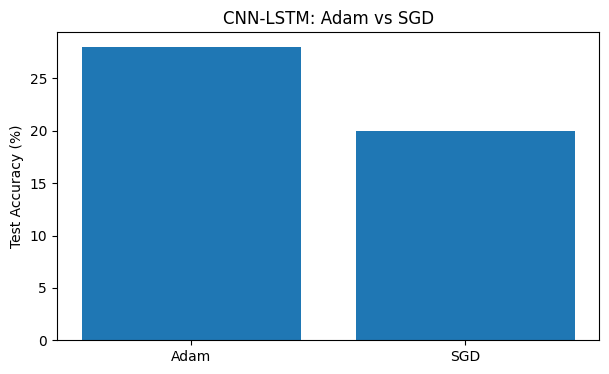

In [38]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
import copy

def optimizer_experiment(opt_name, epochs=5):
    torch.manual_seed(42)

    model = SportsModel("LSTM").to(device)

    if opt_name == "Adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    else:
        optimizer = torch.optim.SGD(
            model.parameters(), lr=0.01, momentum=0.9
        )

    criterion = nn.CrossEntropyLoss()
    best_acc = 0
    best_weights = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):
        model.train()

        for X, y in train_loader:
            X, y = X.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(X), y)
            loss.backward()
            optimizer.step()

        model.eval()
        pred, actual = [], []

        with torch.no_grad():
            for X, y in val_loader:
                pred.extend(model(X.to(device)).argmax(1).cpu().numpy())
                actual.extend(y.numpy())

        acc = accuracy_score(actual, pred)

        if acc > best_acc:
            best_acc = acc
            best_weights = copy.deepcopy(model.state_dict())

        print(f"{opt_name} Epoch {epoch+1}: Validation accuracy = {acc:.4f}")

    model.load_state_dict(best_weights)
    model.eval()

    pred, actual = [], []

    with torch.no_grad():
        for X, y in test_loader:
            pred.extend(model(X.to(device)).argmax(1).cpu().numpy())
            actual.extend(y.numpy())

    test_acc = accuracy_score(actual, pred)
    return best_acc, test_acc

adam_val, adam_test = optimizer_experiment("Adam")
sgd_val, sgd_test = optimizer_experiment("SGD")

print("\nOPTIMIZER COMPARISON")
print(f"Adam - Validation: {adam_val*100:.2f}% | Test: {adam_test*100:.2f}%")
print(f"SGD  - Validation: {sgd_val*100:.2f}% | Test: {sgd_test*100:.2f}%")

plt.figure(figsize=(7, 4))
plt.bar(["Adam", "SGD"], [adam_test*100, sgd_test*100])
plt.ylabel("Test Accuracy (%)")
plt.title("CNN-LSTM: Adam vs SGD")
plt.savefig("/content/sports_action/optimizer_comparison.png")
plt.show()

In [39]:

import torch
import torch.nn as nn
import torchvision.models as models
import copy
import time
from sklearn.metrics import accuracy_score

# Load pretrained ResNet18
weights = models.ResNet18_Weights.DEFAULT
resnet = models.resnet18(weights=weights)

# Freeze pretrained feature extractor
for param in resnet.parameters():
    param.requires_grad = False

# Replace final classification layer
resnet.fc = nn.Linear(resnet.fc.in_features, 6)

class ResNetSports(nn.Module):
    def __init__(self, backbone):
        super().__init__()
        self.backbone = backbone

    def forward(self, x):
        b, t, c, h, w = x.shape
        x = x.reshape(b*t, c, h, w).float() / 255.0

        # ImageNet normalization
        mean = torch.tensor(
            [0.485, 0.456, 0.406], device=x.device
        ).view(1, 3, 1, 1)
        std = torch.tensor(
            [0.229, 0.224, 0.225], device=x.device
        ).view(1, 3, 1, 1)

        x = (x - mean) / std

        features = self.backbone(x)
        features = features.reshape(b, t, 6)

        return features.mean(dim=1)

resnet_model = ResNetSports(resnet).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, resnet_model.parameters()),
    lr=0.001
)

best_acc = 0
best_weights = copy.deepcopy(resnet_model.state_dict())

# Train ResNet18
for epoch in range(5):
    resnet_model.train()
    total_loss = 0

    for X, y in train_loader:
        X, y = X.to(device), y.to(device)

        optimizer.zero_grad()
        output = resnet_model(X)
        loss = criterion(output, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    resnet_model.eval()
    predictions, actual = [], []

    with torch.no_grad():
        for X, y in val_loader:
            output = resnet_model(X.to(device))
            predictions.extend(output.argmax(1).cpu().numpy())
            actual.extend(y.numpy())

    acc = accuracy_score(actual, predictions)

    if acc > best_acc:
        best_acc = acc
        best_weights = copy.deepcopy(resnet_model.state_dict())

    print(
        f"ResNet18 Epoch {epoch+1}/5 | "
        f"Loss: {total_loss/len(train_loader):.4f} | "
        f"Validation Accuracy: {acc:.4f}"
    )

resnet_model.load_state_dict(best_weights)

print("\nResNet18 Best Validation Accuracy:", round(best_acc*100, 2), "%")

torch.save(
    resnet_model.state_dict(),
    "/content/sports_action/models/resnet18.pth"
)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 118MB/s]


ResNet18 Epoch 1/5 | Loss: 1.7245 | Validation Accuracy: 0.4758
ResNet18 Epoch 2/5 | Loss: 1.2775 | Validation Accuracy: 0.6129
ResNet18 Epoch 3/5 | Loss: 0.9718 | Validation Accuracy: 0.8065
ResNet18 Epoch 4/5 | Loss: 0.8611 | Validation Accuracy: 0.7823
ResNet18 Epoch 5/5 | Loss: 0.7332 | Validation Accuracy: 0.8226

ResNet18 Best Validation Accuracy: 82.26 %


In [40]:

!pip -q install fvcore

from fvcore.nn import FlopCountAnalysis
import time
import torch
import numpy as np
from sklearn.metrics import accuracy_score

# 1. Evaluate ResNet18 on test data
resnet_model.eval()
predictions, actual = [], []

with torch.no_grad():
    for X, y in test_loader:
        output = resnet_model(X.to(device))
        predictions.extend(output.argmax(1).cpu().numpy())
        actual.extend(y.numpy())

resnet_test_acc = accuracy_score(actual, predictions)

print("ResNet18 Test Accuracy:",
      round(resnet_test_acc * 100, 2), "%")

# 2. Compare custom CNN and ResNet18
sample = next(iter(test_loader))[0][:1].to(device)

comparison_models = {
    "Custom CNN": models["CNN"],
    "Pretrained ResNet18": resnet_model
}

def measure_model(model, sample):
    model.eval()

    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(
        p.numel() for p in model.parameters() if p.requires_grad
    )

    # FLOPs for one video
    flops = FlopCountAnalysis(model, sample).total()

    # Measure inference time
    with torch.no_grad():
        for _ in range(5):
            model(sample)

        if device.type == "cuda":
            torch.cuda.synchronize()

        start = time.time()

        for _ in range(30):
            model(sample)

        if device.type == "cuda":
            torch.cuda.synchronize()

        latency = (time.time() - start) / 30 * 1000

    return total_params, trainable_params, flops, latency

print("\nMODEL COMPUTATIONAL COMPARISON")

for name, model in comparison_models.items():
    total, trainable, flops, latency = measure_model(model, sample)

    print("\n", name)
    print("Total parameters:", f"{total:,}")
    print("Trainable parameters:", f"{trainable:,}")
    print("FLOPs per video:", f"{flops/1e6:.2f} Million")
    print("Inference time:", f"{latency:.2f} ms")


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ResNet18 Test Accuracy: 80.0 %


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


TypeError: 'module' object is not subscriptable

In [41]:
from fvcore.nn import FlopCountAnalysis
import time
import torch

# Recreate custom CNN architecture for complexity measurement
custom_cnn = SportsModel("CNN").to(device)

comparison_models = {
    "Custom CNN": custom_cnn,
    "Pretrained ResNet18": resnet_model
}

sample = next(iter(test_loader))[0][:1].to(device)

def measure_model(model, sample):
    model.eval()

    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(
        p.numel() for p in model.parameters() if p.requires_grad
    )

    flops = FlopCountAnalysis(model, sample).total()

    with torch.no_grad():
        for _ in range(5):
            model(sample)

        if device.type == "cuda":
            torch.cuda.synchronize()

        start = time.time()

        for _ in range(30):
            model(sample)

        if device.type == "cuda":
            torch.cuda.synchronize()

        latency = (time.time() - start) / 30 * 1000

    return total_params, trainable_params, flops, latency

for name, model in comparison_models.items():
    total, trainable, flops, latency = measure_model(model, sample)

    print("\n", name)
    print("Total parameters:", f"{total:,}")
    print("Trainable parameters:", f"{trainable:,}")
    print("FLOPs per video:", f"{flops/1e6:.2f} Million")
    print("Inference time:", f"{latency:.2f} ms")


 Custom CNN
Total parameters: 94,022
Trainable parameters: 94,022
FLOPs per video: 165.28 Million
Inference time: 2.34 ms



 Pretrained ResNet18
Total parameters: 11,179,590
Trainable parameters: 3,078
FLOPs per video: 593.83 Million
Inference time: 10.48 ms



Testing LR=0.001, Batch Size=16
Validation accuracy: 34.68 %

Testing LR=0.001, Batch Size=32
Validation accuracy: 27.42 %

Testing LR=0.0005, Batch Size=16
Validation accuracy: 33.06 %

Testing LR=0.0005, Batch Size=32
Validation accuracy: 29.03 %

TUNING RESULTS
 Learning Rate  Batch Size  Validation Accuracy
        0.0010          16                34.68
        0.0010          32                27.42
        0.0005          16                33.06
        0.0005          32                29.03

BEST CONFIGURATION
Learning rate: 0.001
Batch size: 16
Best validation accuracy: 34.68 %
Selected model test accuracy: 32.8 %


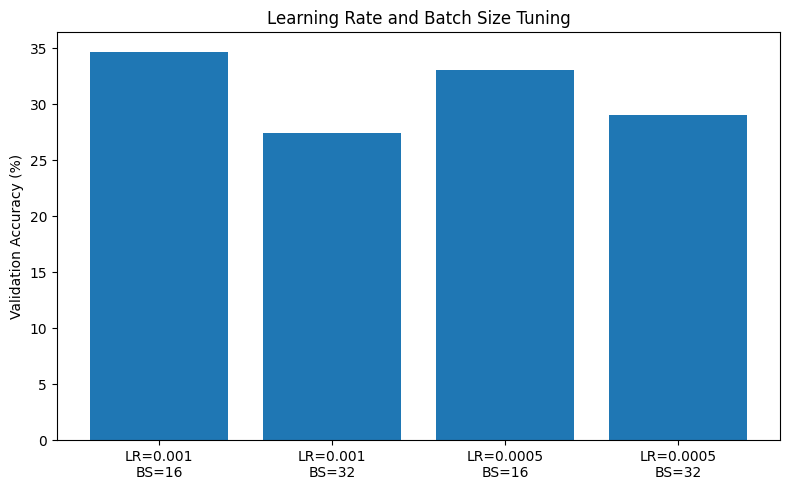

In [42]:

import torch
import torch.nn as nn
import copy
import pandas as pd
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score

train_dataset = SportsDataset(data["X_train"], data["y_train"])
val_dataset = SportsDataset(data["X_val"], data["y_val"])

configurations = [
    (0.001, 16),
    (0.001, 32),
    (0.0005, 16),
    (0.0005, 32)
]

tuning_results = []
best_score = -1
best_model = None
best_config = None

for lr, batch_size in configurations:

    print(f"\nTesting LR={lr}, Batch Size={batch_size}")

    torch.manual_seed(42)

    train_dl = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True
    )
    val_dl = DataLoader(
        val_dataset, batch_size=32, shuffle=False
    )

    model = SportsModel("LSTM").to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    for epoch in range(3):
        model.train()

        for X, y in train_dl:
            X, y = X.to(device), y.to(device)

            optimizer.zero_grad()
            loss = criterion(model(X), y)
            loss.backward()
            optimizer.step()

    model.eval()
    predictions, actual = [], []

    with torch.no_grad():
        for X, y in val_dl:
            output = model(X.to(device))
            predictions.extend(output.argmax(1).cpu().numpy())
            actual.extend(y.numpy())

    val_acc = accuracy_score(actual, predictions)

    print("Validation accuracy:", round(val_acc * 100, 2), "%")

    tuning_results.append({
        "Learning Rate": lr,
        "Batch Size": batch_size,
        "Validation Accuracy": round(val_acc * 100, 2)
    })

    if val_acc > best_score:
        best_score = val_acc
        best_model = copy.deepcopy(model.state_dict())
        best_config = (lr, batch_size)

# Select best configuration
print("\nTUNING RESULTS")
tuning_df = pd.DataFrame(tuning_results)
print(tuning_df.to_string(index=False))

# Evaluate selected model on held-out test data
selected_model = SportsModel("LSTM").to(device)
selected_model.load_state_dict(best_model)
selected_model.eval()

predictions, actual = [], []

with torch.no_grad():
    for X, y in test_loader:
        output = selected_model(X.to(device))
        predictions.extend(output.argmax(1).cpu().numpy())
        actual.extend(y.numpy())

final_test_acc = accuracy_score(actual, predictions)

print("\nBEST CONFIGURATION")
print("Learning rate:", best_config[0])
print("Batch size:", best_config[1])
print("Best validation accuracy:", round(best_score * 100, 2), "%")
print("Selected model test accuracy:", round(final_test_acc * 100, 2), "%")

# Plot tuning results
plt.figure(figsize=(8, 5))
labels = [
    f"LR={r['Learning Rate']}\nBS={r['Batch Size']}"
    for r in tuning_results
]
values = [r["Validation Accuracy"] for r in tuning_results]

plt.bar(labels, values)
plt.ylabel("Validation Accuracy (%)")
plt.title("Learning Rate and Batch Size Tuning")
plt.tight_layout()
plt.savefig("/content/sports_action/tuning_comparison.png")
plt.show()
